# TSLA — Four-model forecasting comparison
**AMS 586 · One-step-ahead closing-price forecasts**

This presentation notebook is **read-only**: it consumes the frozen test CSVs and the append-only prospective forecast histories exported by the four individual model notebooks. It does **not** download prices, refit models, change parameters, or overwrite forecasts. Run each model notebook first when fresh forecasts are needed.

**Experimental protocol:** train → validation (hyperparameter selection and empirical residual calibration) → frozen test (258 daily targets, ending November 19, 2026) → prospective forecasts. Intervals are nominal 95% empirical residual-shift intervals; nominal coverage is not a guarantee of conditional coverage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

# Locate project root regardless of whether notebook is run from root or stock_pred/notebooks.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "stock_pred" / "results").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project containing stock_pred/results")
RESULTS_DIR = PROJECT_ROOT / "stock_pred" / "results"

MODEL_FILES = {
    "Random Walk": "random_walk",
    "Random Walk + Drift": "random_walk_drift",
    "ARIMA(0,1,1)": "arima",
    "MLP": "mlp",
}
INTERVAL_LEVEL = 0.95
EXPECTED_TEST_COUNT = 258
TEST_END_DATE = pd.Timestamp("2026-11-19")
print("Reading exported results from:", RESULTS_DIR)

Reading exported results from: /Users/jss/Desktop/code/python/environments/timeseriesproj/stock_pred/results


## 1 · Load and validate the exported datasets
The comparison requires **identical test target dates and actual prices** for every model. It fails rather than silently comparing mismatched experiments.

In [2]:
REQUIRED = ["origin_date", "target_date", "model", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]

def load_result(prefix, suffix):
    path = RESULTS_DIR / f"{prefix}_{suffix}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run the corresponding model notebook first.")
    df = pd.read_csv(path, parse_dates=["origin_date", "target_date"])
    missing = set(REQUIRED) - set(df.columns)
    if missing:
        raise ValueError(f"{path.name}: missing {sorted(missing)}")
    if df["target_date"].duplicated().any():
        raise ValueError(f"{path.name}: duplicate target dates; inspect before comparing")
    if not (df["origin_date"] < df["target_date"]).all():
        raise ValueError(f"{path.name}: origin must precede target")
    for col in REQUIRED[3:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.sort_values("target_date").reset_index(drop=True)

tests = {name: load_result(prefix, "test") for name, prefix in MODEL_FILES.items()}
live = {name: load_result(prefix, "live_history") for name, prefix in MODEL_FILES.items()}

reference = tests["Random Walk"]
assert len(reference) == EXPECTED_TEST_COUNT, f"Expected {EXPECTED_TEST_COUNT} test targets; got {len(reference)}"
assert reference["target_date"].max() == TEST_END_DATE
for name, df in tests.items():
    pd.testing.assert_series_equal(df["target_date"], reference["target_date"], check_names=False)
    np.testing.assert_allclose(df["y_true"], reference["y_true"], rtol=0, atol=1e-6)
    if df[["y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].isna().any().any():
        raise ValueError(f"{name}: missing values in frozen test predictions")
    if (df["interval_lower"] > df["interval_upper"]).any():
        raise ValueError(f"{name}: inverted intervals")

print(f"Validated {len(reference)} identical test targets: {reference.target_date.min().date()} to {reference.target_date.max().date()}")
display(pd.DataFrame([{"Model": name, "Test rows": len(tests[name]),
                       "Prospective rows": len(live[name]),
                       "Latest prospective target": live[name].target_date.max().date() if len(live[name]) else None}
                      for name in MODEL_FILES]))

Validated 258 identical test targets: 2025-11-11 to 2026-11-19


,Model,Test rows,Prospective rows,Latest prospective target
0,Random Walk,258,2,2026-11-23
1,Random Walk + Drift,258,1,2026-11-23
2,"ARIMA(0,1,1)",258,1,2026-11-23
3,MLP,258,1,2026-11-23


## 2 · Held-out test performance
All point metrics are evaluated against the **same actual closing prices**. The empirical predictive mean is also evaluated as a separate point forecast. The MSE and RMSE optimize squared-error accuracy; MAE reports average absolute error in dollars.

**Coverage** is the fraction of observed closes inside the nominal 95% prediction interval. **Width** measures how informative the interval is. Wider intervals can increase coverage without improving precision.

In [3]:
def score_forecasts(df):
    actual = df["y_true"].to_numpy(float)
    pred = df["y_pred"].to_numpy(float)
    pm = df["predictive_mean"].to_numpy(float)
    err = actual - pred
    covered = (actual >= df["interval_lower"].to_numpy(float)) & (actual <= df["interval_upper"].to_numpy(float))
    return {
        "RMSE ($)": np.sqrt(np.mean(err**2)),
        "MAE ($)": np.mean(np.abs(err)),
        "MSE ($²)": np.mean(err**2),
        "Bias ($)": np.mean(err),
        "Predictive mean RMSE ($)": np.sqrt(np.mean((actual - pm)**2)),
        "Coverage (%)": 100*np.mean(covered),
        "Avg interval width ($)": np.mean(df["interval_upper"]-df["interval_lower"]),
    }

scores = pd.DataFrame({name: score_forecasts(df) for name, df in tests.items()}).T
scores.index.name = "Model"
scores = scores.sort_values("RMSE ($)")
display(scores.round(3))
print("Lowest test RMSE:", scores.index[0], "(descriptive only: do not retune models using the test set)")

,RMSE ($),MAE ($),MSE ($²),Bias ($),Predictive mean RMSE ($),Coverage (%),Avg interval width ($)
Model,,,,,,,
Random Walk,11.239,8.479,126.305,-0.274,11.268,97.287,51.690
"ARIMA(0,1,1)",11.259,8.552,126.756,-0.302,11.289,97.287,50.552
Random Walk + Drift,11.271,8.482,127.040,-0.455,11.273,97.287,51.741
MLP,11.559,8.781,133.600,-0.573,11.550,97.287,54.635


Lowest test RMSE: Random Walk (descriptive only: do not retune models using the test set)


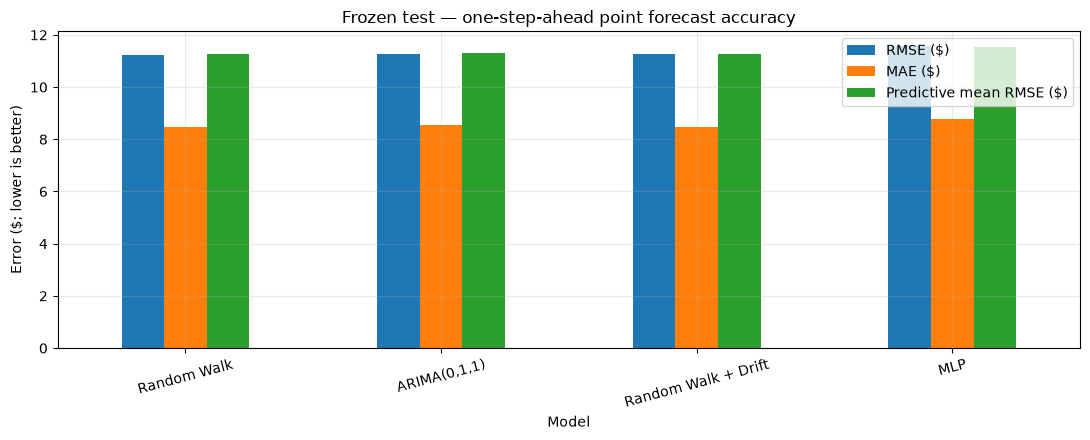

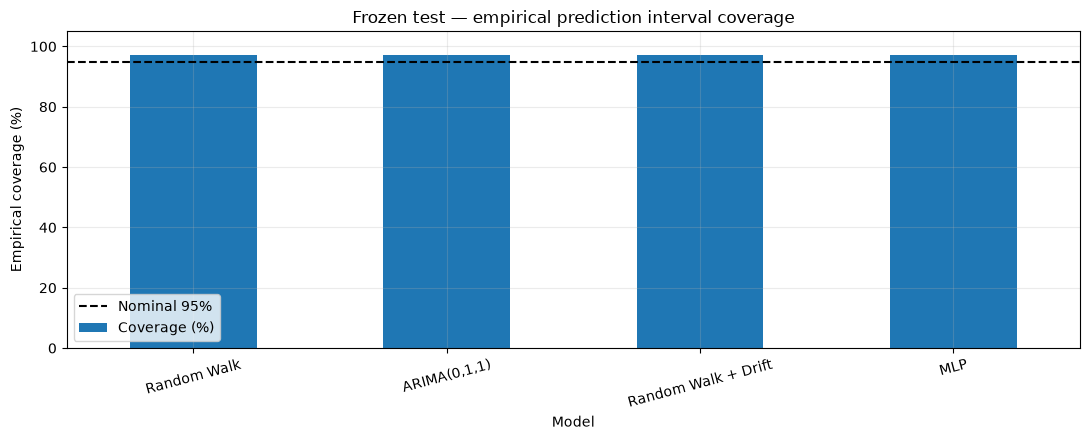

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
scores[["RMSE ($)", "MAE ($)", "Predictive mean RMSE ($)"]].plot.bar(ax=ax, rot=15)
ax.set_title("Frozen test — one-step-ahead point forecast accuracy")
ax.set_ylabel("Error ($; lower is better)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
scores["Coverage (%)"].plot.bar(ax=ax, rot=15)
ax.axhline(100*INTERVAL_LEVEL, color="black", linestyle="--", label="Nominal 95%")
ax.set_ylim(0, 105); ax.set_ylabel("Empirical coverage (%)")
ax.set_title("Frozen test — empirical prediction interval coverage")
ax.legend(); plt.tight_layout(); plt.show()

## 3 · Aligned actual vs. forecast paths
These plots share identical test dates. The display is restricted to the last 75 test sessions for readability; the metrics above use **all 258** sessions.

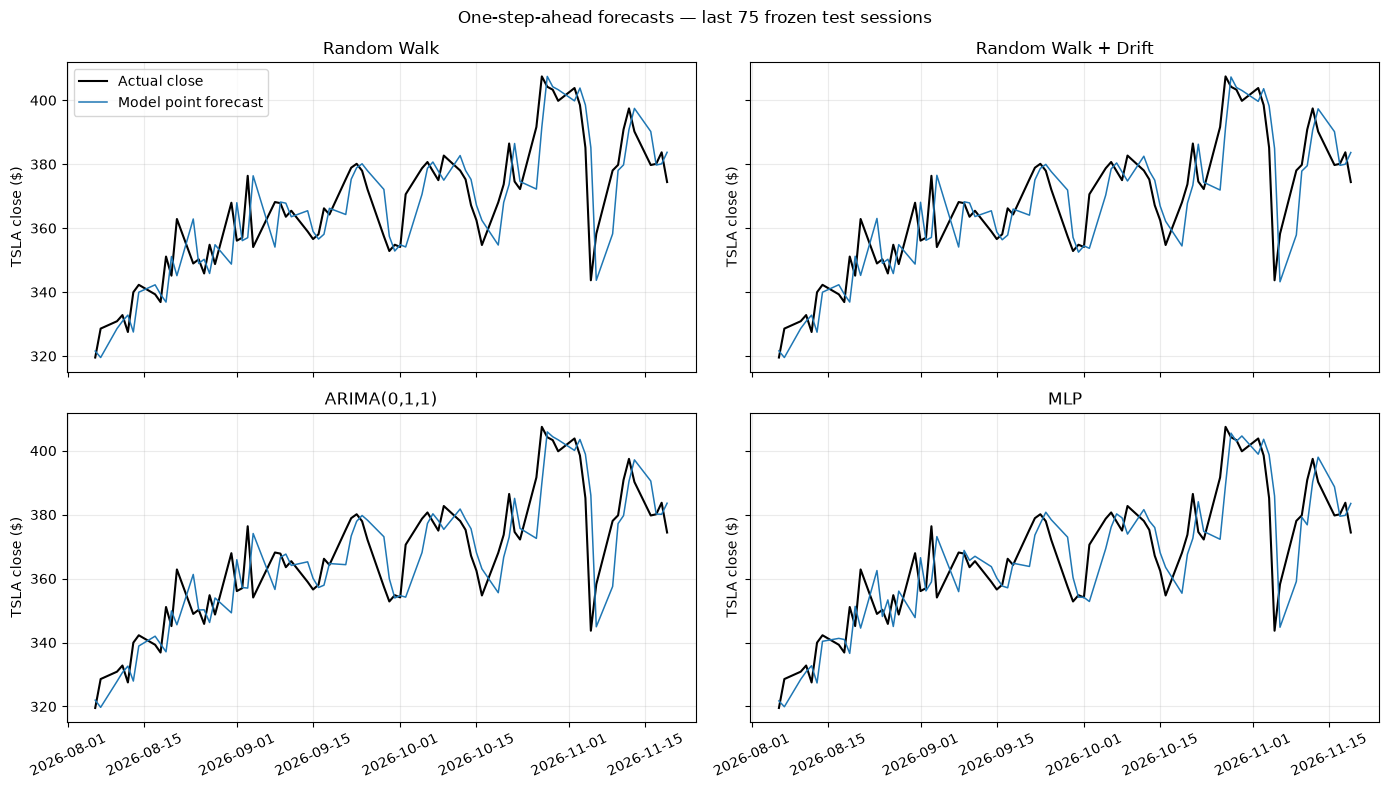

In [5]:
last_n = 75
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    view = df.tail(last_n)
    ax.plot(view.target_date, view.y_true, label="Actual close", color="black", lw=1.5)
    ax.plot(view.target_date, view.y_pred, label="Model point forecast", lw=1.1)
    ax.set_title(name); ax.set_ylabel("TSLA close ($)")
    ax.tick_params(axis="x", rotation=25)
axes.flat[0].legend(loc="best")
fig.suptitle("One-step-ahead forecasts — last 75 frozen test sessions")
plt.tight_layout(); plt.show()

## 4 · Forecast-error diagnostics
The signed forecast error is $e_t=P_t-\widehat P_{t|t-1}$. A small **mean** error does not imply small individual errors. RMSE squares before averaging; MAE takes absolute values before averaging.

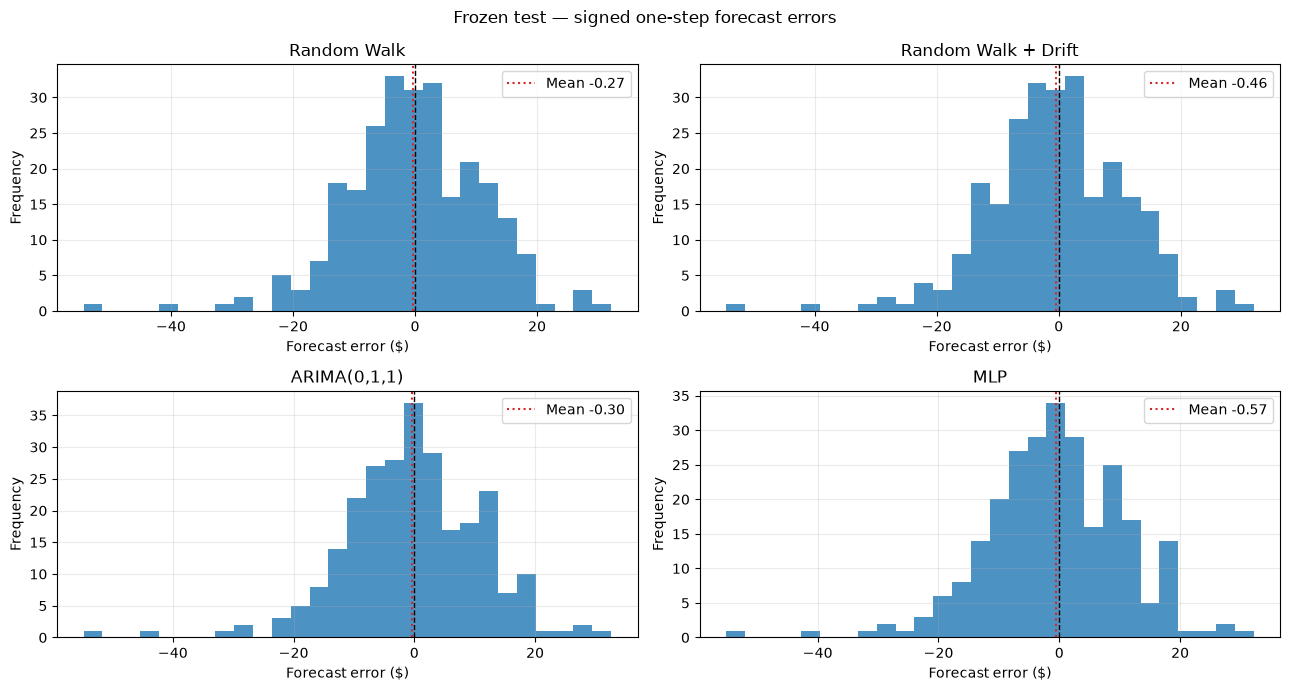

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (name, df) in zip(axes.flat, tests.items()):
    errors = df.y_true - df.y_pred
    ax.hist(errors, bins=28, alpha=0.8)
    ax.axvline(0, color="black", linestyle="--", lw=1)
    ax.axvline(errors.mean(), color="tab:red", linestyle=":", lw=1.5, label=f"Mean {errors.mean():.2f}")
    ax.set_title(name); ax.set_xlabel("Forecast error ($)"); ax.set_ylabel("Frequency"); ax.legend()
fig.suptitle("Frozen test — signed one-step forecast errors")
plt.tight_layout(); plt.show()

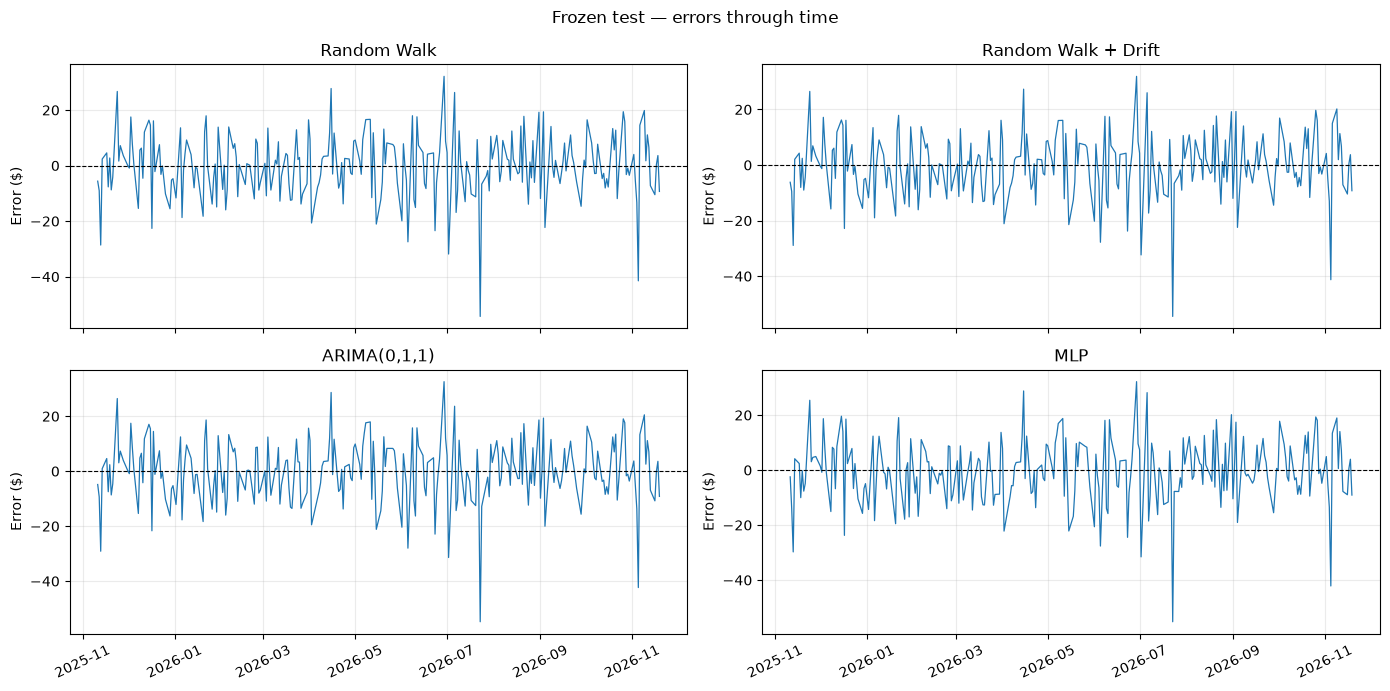

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    errors = df.y_true - df.y_pred
    ax.plot(df.target_date, errors, lw=0.9)
    ax.axhline(0, color="black", linestyle="--", lw=0.8)
    ax.set_title(name); ax.set_ylabel("Error ($)"); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Frozen test — errors through time")
plt.tight_layout(); plt.show()

## 5 · Prediction intervals: coverage versus width
Display the last 50 frozen test targets with the empirical residual-shift prediction intervals. These are **prediction intervals for future closing prices**, not confidence intervals for model parameters.

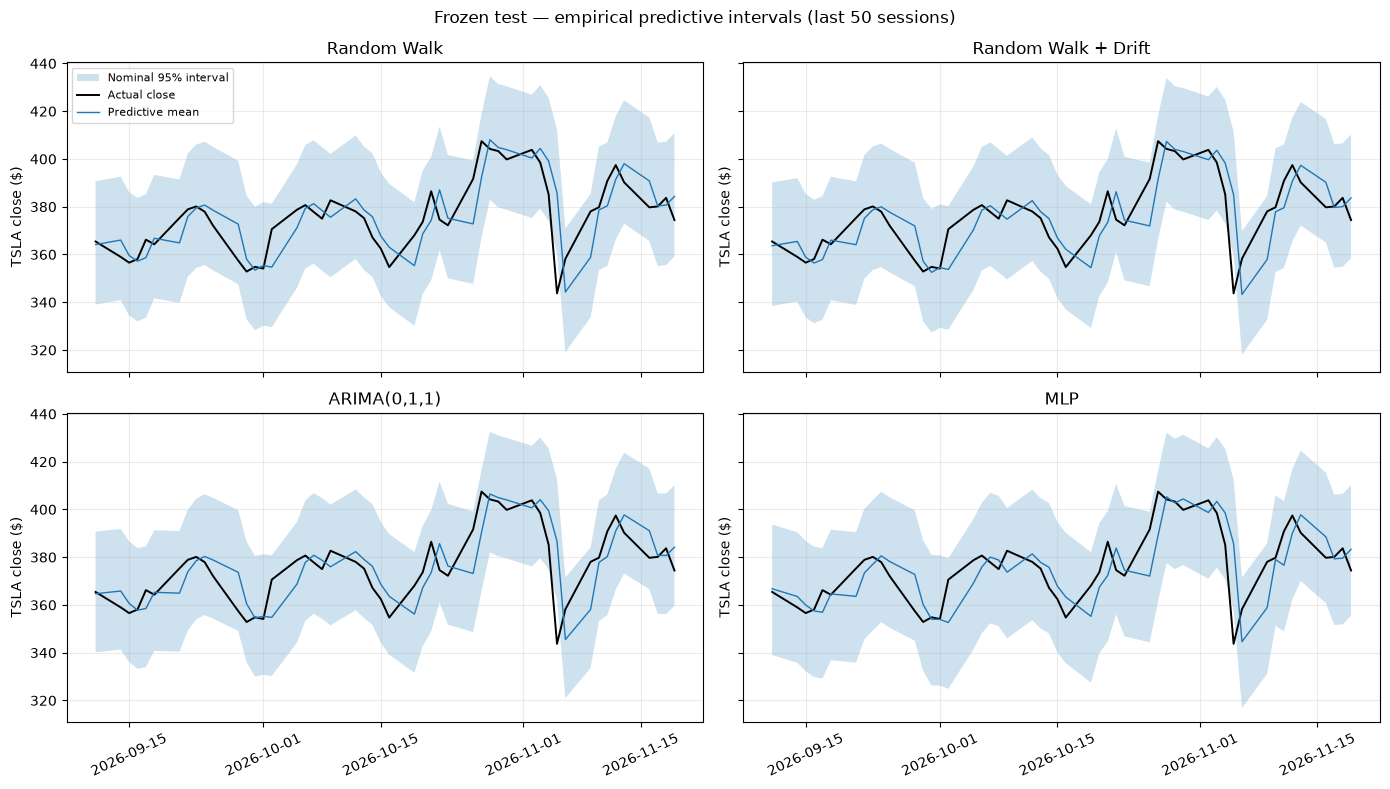

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    view = df.tail(50)
    ax.fill_between(view.target_date, view.interval_lower.to_numpy(), view.interval_upper.to_numpy(), alpha=0.22, label="Nominal 95% interval")
    ax.plot(view.target_date, view.y_true, color="black", lw=1.4, label="Actual close")
    ax.plot(view.target_date, view.predictive_mean, lw=1.0, label="Predictive mean")
    ax.set_title(name); ax.set_ylabel("TSLA close ($)"); ax.tick_params(axis="x", rotation=25)
axes.flat[0].legend(loc="best", fontsize=8)
fig.suptitle("Frozen test — empirical predictive intervals (last 50 sessions)")
plt.tight_layout(); plt.show()

## 6 · Prospective forecasts (issued before the outcome)
The tables below are read directly from the model-specific append-only histories. **Only realized outcomes may be filled in later; issued predictions must not be retroactively replaced.** If model histories do not yet contain the same latest target, the dashboard shows only their latest *common* target.

In [9]:
# Display all most-recent issued rows first; helps diagnose lagging model notebooks.
latest_issued = pd.concat([df.tail(1).assign(display_model=name) for name, df in live.items() if not df.empty], ignore_index=True)
if latest_issued.empty:
    print("No prospective forecasts have been exported yet.")
else:
    display(latest_issued[["display_model", "origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].round(3))

common_targets = set.intersection(*(set(df.target_date) for df in live.values())) if all(len(df) for df in live.values()) else set()
if not common_targets:
    print("No common prospective target across all four models. Run the missing model notebooks first.")
    live_dashboard = pd.DataFrame()
else:
    common_target = max(common_targets)
    live_dashboard = pd.DataFrame([
        {"Model": name, **df.loc[df.target_date.eq(common_target),
         ["origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].iloc[-1].to_dict()}
        for name, df in live.items()
    ]).set_index("Model")
    print("Latest common prospective target:", common_target.date())
    display(live_dashboard.round(3))

/var/folders/bg/xcplsl7s3_lb168_wsrgyv440000gn/T/ipykernel_77683/3437796489.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(latest_issued[["display_model", "origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].round(3))


,display_model,origin_date,target_date,y_true,y_pred,predictive_mean,interval_lower,interval_upper
0,Random Walk,2026-11-20,2026-11-23,NaN,345.820,346.411,321.260,372.950
1,Random Walk + Drift,2026-11-20,2026-11-23,NaN,345.623,345.665,320.444,372.185
2,"ARIMA(0,1,1)",2026-11-20,2026-11-23,NaN,346.729,347.304,322.767,373.319
3,MLP,2026-11-20,2026-11-23,NaN,346.117,345.917,318.169,372.803


Latest common prospective target: 2026-11-23


/var/folders/bg/xcplsl7s3_lb168_wsrgyv440000gn/T/ipykernel_77683/3437796489.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(live_dashboard.round(3))


,origin_date,target_date,y_true,y_pred,predictive_mean,interval_lower,interval_upper
Model,,,,,,,
Random Walk,2026-11-20,2026-11-23,NaN,345.820,346.411,321.260,372.950
Random Walk + Drift,2026-11-20,2026-11-23,NaN,345.623,345.665,320.444,372.185
"ARIMA(0,1,1)",2026-11-20,2026-11-23,NaN,346.729,347.304,322.767,373.319
MLP,2026-11-20,2026-11-23,NaN,346.117,345.917,318.169,372.803


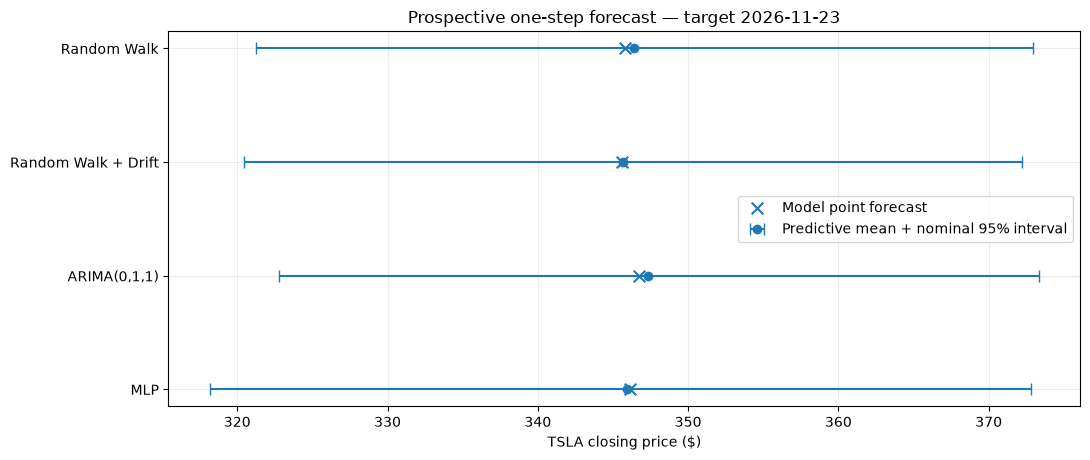

In [10]:
if not live_dashboard.empty:
    fig, ax = plt.subplots(figsize=(11, 4.7))
    order = list(MODEL_FILES)
    display_df = live_dashboard.loc[order]
    y = np.arange(len(order))
    means = display_df["predictive_mean"].to_numpy(float)
    lower = display_df["interval_lower"].to_numpy(float)
    upper = display_df["interval_upper"].to_numpy(float)
    ax.errorbar(means, y, xerr=np.vstack([means-lower, upper-means]),
                fmt="o", capsize=4, label="Predictive mean + nominal 95% interval")
    ax.scatter(display_df["y_pred"], y, marker="x", s=70, label="Model point forecast")
    if display_df["y_true"].notna().all():
        ax.axvline(float(display_df["y_true"].iloc[0]), color="black", ls="--", label="Realized close")
    ax.set_yticks(y, order); ax.invert_yaxis(); ax.set_xlabel("TSLA closing price ($)")
    ax.set_title(f"Prospective one-step forecast — target {common_target.date()}")
    ax.legend(); plt.tight_layout(); plt.show()

## 7 · Interpretation and limitations

- **MMSE principle:** The conditional expectation minimizes expected squared error among forecasts measurable with respect to available information. Here we *approximate* this objective by minimizing validation MSE/RMSE over candidate forecasting procedures.
- **Predictive mean correction:** The empirical predictive mean equals the model point forecast plus the **mean signed validation residual**. A small correction does not imply low volatility or small RMSE.
- **Calibration:** Empirical validation residuals are shifted to obtain prediction intervals. They assume historical residual behavior is informative about future forecast errors; volatility changes can cause miscoverage. Using the same validation period for hyperparameter selection and interval calibration can introduce optimistic bias.
- **Comparability:** All reported test metrics use identical frozen targets. Test data are not used for model selection.
- **Prospective integrity:** Each model's forecast must be issued before its target close; results are not overwritten after observing the outcome.

**Presentation workflow:** run individual model notebooks to refresh and export prospective forecasts; then run this notebook for fast, reproducible comparisons. This notebook performs no model fitting or downloads.